```markdown
### Step 1: Loading Datasets

This initial step reads the source files into memory. This provides our base transactional, customer, and product datasets.

**Variables Loaded:**
* **`customer_orders_df`** *(DataFrame)*: General order registry mapping orders to customer IDs, brands, and channels.
* **`returns_df`** *(DataFrame)*: Return records mapping back to specific orders with details like return dates and courier details.
* **`returns_by_sku_df`** *(DataFrame)*: SKU performance aggregates charting sales versus returns.
* **`order_lines_df`** *(DataFrame)*: Line-item level details containing units sold, price, discount, and return statuses.
```

In [11]:
# [Markdown Explanation of this step]
"""
### Step 1: Loading Datasets
**Variables Loaded:**
- `customer_orders_df`: Customer order profiles (dates, brands, channels, postcodes).
- `returns_df`: Individual customer return transactions (reasons, refunds, costs).
- `returns_by_sku_df`: Aggregate return statistics grouped by specific stock keeping units (SKUs).
- `order_lines_df`: Granular itemized transaction lines per order.
"""

import pandas as pd

customer_orders_df = pd.read_excel('/content/Project 4 & 5 - customer orders.xlsx')
returns_df = pd.read_excel('/content/Project 4 & 5 - Returns.xlsx')
returns_by_sku_df = pd.read_csv('/content/Loft25_BCU_05_P4_returns_by_SKU.csv')
order_lines_df = pd.read_csv('/content/Loft25_BCU_04_P4_order_lines.csv')

print("=== Customer Orders Summary ===")
display(customer_orders_df.head())
customer_orders_df.info()

=== Customer Orders Summary ===


,Order ref,Customer ref,Order date,Brand,Channel,Postcode area
0,O000011,C000001,2025-01-05,Gardenista,eBay,SW16
1,O000012,C000002,2025-01-06,Gardenista,Website (Shopify),SW10
2,O000013,C000003,2025-01-06,Gardenista,Website (Shopify),KT3
3,O000014,C000004,2025-01-06,Gardenista,Amazon,BH4
4,O000015,C000005,2025-01-06,Gardenista,Website (Shopify),W2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31410 entries, 0 to 31409
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ref      31410 non-null  object        
 1   Customer ref   31410 non-null  object        
 2   Order date     31410 non-null  datetime64[ns]
 3   Brand          31410 non-null  object        
 4   Channel        31410 non-null  object        
 5   Postcode area  31410 non-null  object        
dtypes: datetime64[ns](1), object(5)
memory usage: 1.4+ MB


```markdown
### Step 2: Data Quality & Missing Value Inspection

This inspection maps out the presence of null values across our tables to locate where cleaning is required.

**Variables Inspected:**
* **`datasets`** *(dict)*: Dictionary container keying titles to dataframes for loop analysis.
* **`missing_counts`** *(Series)*: Total null elements found inside each column.
* **`missing_percentage`** *(Series)*: Relative share of missing values relative to absolute row counts.
```

```markdown
### Global Variable Directory and Workflow Reference

Below is an overview of the key datasets and variables managed throughout this notebook:

#### 1. Input Datasets
* **`customer_orders_df`**: Contains general customer profile fields (`Order ref`, `Customer ref`, `Order date`, `Brand`, `Channel`, `Postcode area`). Used as the master register of order metadata.
* **`order_lines_df`**: Itemized lines representing products within each order (`Order ref`, `SKU`, `Qty`, `Unit price inc VAT`, `Line value inc VAT`, `Line discount`, and the target label `Returned`).
* **`returns_df`**: Customer returns tracking including exact return dates, courier details, and refund amounts.
* **`returns_by_sku_df`**: SKU-level metrics aggregates detailing units sold versus returned.

#### 2. Model Feature Matrix & Splitting
* **`model_df`**: Cleaned, label-encoded copy of the order lines data utilized for downstream modeling.
* **`X`**: Preprocessed independent feature dimensions containing:
  * `Brand` and `Channel` (label encoded)
  * `Qty` (Quantity purchased)
  * `Unit price inc VAT`
  * `Line value inc VAT`
  * `Line discount`
* **`y`**: Independent binary target column (`Returned`), where `1` indicates a return and `0` indicates no return.
* **`X_train_scaled` / `X_test_scaled`**: Standardized feature inputs designed to eliminate scale-biases in our Logistic Regression, XGBoost, and TabNet classifier algorithms.

#### 3. Prediction Outputs
* **`lr_preds` / `lr_probs`**: Logistic regression discrete label classifications and corresponding probability predictions.
* **`xgb_preds` / `xgb_probs`**: Extreme Gradient Boosting classifications and corresponding probability predictions.
* **`tabnet_preds` / `tabnet_probs`**: Deep tabular network model classifications and corresponding probability predictions.
```

In [12]:
# [Markdown Explanation of this step]
"""
### Step 2: Data Quality & Missing Value Inspection
**Variables Inspected:**
- `datasets`: Dictionary pairing each dataset with its descriptive label.
- `missing_counts`: Evaluates the sum of null elements per column.
- `missing_percentage`: Computes the proportion of missing entries relative to the dataset length.
"""

datasets = {
    "Customer Orders": customer_orders_df,
    "Returns": returns_df,
    "Returns by SKU": returns_by_sku_df,
    "Order Lines": order_lines_df
}

for name, df in datasets.items():
    print(f"=== Missing Values in '{name}' ===")
    missing_counts = df.isnull().sum()
    missing_percentage = (df.isnull().sum() / len(df)) * 100
    missing_df = pd.DataFrame({
        'Missing Count': missing_counts,
        'Percentage (%)': missing_percentage
    })
    display(missing_df[missing_df['Missing Count'] > 0] if missing_counts.sum() > 0 else "No missing values found in this dataset.\n")

=== Missing Values in 'Customer Orders' ===


'No missing values found in this dataset.\n'

=== Missing Values in 'Returns' ===


,Missing Count,Percentage (%)
Unnamed: 14,1523,100.0


=== Missing Values in 'Returns by SKU' ===


'No missing values found in this dataset.\n'

=== Missing Values in 'Order Lines' ===


'No missing values found in this dataset.\n'

```markdown
### Step 3: Cleaning & Resolving Quality Issues

This action drops empty placeholders to keep calculations accurate and memory clean.

**Variables Cleaned:**
* **`returns_df`** *(DataFrame)*: In-place modified dataframe with empty structures removed (specifically dropping `Unnamed: 14`).
```

In [13]:
# [Markdown Explanation of this step]
"""
### Step 3: Cleaning & Resolving Quality Issues
**Variables Cleaned:**
- `returns_df`: Modifying the dataset in-place by removing 'Unnamed: 14' which contains only null values.
"""

print("Original Returns columns:", returns_df.shape)
if 'Unnamed: 14' in returns_df.columns:
    returns_df = returns_df.drop(columns=['Unnamed: 14'])
    print("Dropped 'Unnamed: 14' from Returns dataset.")

print("Updated Returns columns:", returns_df.shape)
print("Remaining missing values in Returns:")
print(returns_df.isnull().sum()[returns_df.isnull().sum() > 0])

Original Returns columns: (1523, 20)
Dropped 'Unnamed: 14' from Returns dataset.
Updated Returns columns: (1523, 19)
Remaining missing values in Returns:
Series([], dtype: int64)


```markdown
### Step 4: Preparing Features for Machine Learning Models

This step prepares, encodes, scales, and partitions our feature parameters for training.

**Variables Configured:**
* **`model_df`** *(DataFrame)*: Working dataframe representing processed features.
* **`X`** *(DataFrame)* & **`y`** *(Series)*: Feature matrix containing encoded attributes (`Brand`, `Channel`, quantities, prices) and target arrays mapping class status.
* **`X_train_scaled` / `X_test_scaled`** *(ndarray)*: Scaled, standardized subsets used to feed classifiers.
```

In [14]:
# [Markdown Explanation of this step]
"""
### Step 4: Preparing Features for Machine Learning Models
**Variables Configured:**
- `model_df`: Copied from `order_lines_df` for modeling preprocessing.
- `X`, `y`: Feature matrix containing encoded categories, transaction values, and the binary target target (`Returned`).
- `X_train_scaled`, `X_test_scaled`: Standardized subsets ensuring features are normalized for scaling-sensitive classifiers.
"""

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

model_df = order_lines_df.copy()

le_brand = LabelEncoder()
model_df['Brand'] = le_brand.fit_transform(model_df['Brand'])

le_channel = LabelEncoder()
model_df['Channel'] = le_channel.fit_transform(model_df['Channel'])

features = ['Brand', 'Channel', 'Qty', 'Unit price inc VAT', 'Line value inc VAT', 'Line discount']
X = model_df[features].fillna(0)
y = model_df['Returned'].fillna(0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Data prepared. Train shape:", X_train.shape, "Test shape:", X_test.shape)

Data prepared. Train shape: (27444, 6) Test shape: (6861, 6)


```markdown
### Step 5: Training and Assessing Logistic Regression

This step initializes and trains a baseline classification model to map probability relationships linearly.

**Variables Used:**
* **`lr_model`** *(LogisticRegression)*: Linear regression model pipeline.
* **`lr_preds`** / **`lr_probs`** *(ndarray)*: Discretized prediction outcomes and class 1 decision probabilities.
```

In [15]:
# [Markdown Explanation of this step]
"""
### Step 5: Training and Assessing Logistic Regression
**Variables Used:**
- `lr_model`: A linear baseline classification pipeline.
- `lr_preds`, `lr_probs`: Holds classification outcomes and probability metrics to score model ROC AUC.
"""

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression Results ===")
print(classification_report(y_test, lr_preds))
print(f"ROC AUC Score: {roc_auc_score(y_test, lr_probs):.4f}")

=== Logistic Regression Results ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      6554
           1       0.00      0.00      0.00       307

    accuracy                           0.96      6861
   macro avg       0.48      0.50      0.49      6861
weighted avg       0.91      0.96      0.93      6861

ROC AUC Score: 0.5915


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


```markdown
### Step 6: Training and Assessing XGBoost Classifier

This step runs an optimized gradient-boosted decision tree algorithm to trace non-linear classification rules.

**Variables Used:**
* **`xgb_model`** *(XGBClassifier)*: Gradient boosting ensemble pipeline.
* **`xgb_preds`** / **`xgb_probs`** *(ndarray)*: Test predicted classes and probabilities.
```

In [16]:
# [Markdown Explanation of this step]
"""
### Step 6: Training and Assessing XGBoost Classifier
**Variables Used:**
- `xgb_model`: Ensemble decision trees to handle complex interactions among transactions features.
- `xgb_preds`, `xgb_probs`: Predictions evaluated for performance benchmarks.
"""

from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_scaled, y_train)

xgb_preds = xgb_model.predict(X_test_scaled)
xgb_probs = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("=== XGBoost Results ===")
print(classification_report(y_test, xgb_preds))
print(f"ROC AUC Score: {roc_auc_score(y_test, xgb_probs):.4f}")

=== XGBoost Results ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      6554
           1       0.00      0.00      0.00       307

    accuracy                           0.95      6861
   macro avg       0.48      0.50      0.49      6861
weighted avg       0.91      0.95      0.93      6861

ROC AUC Score: 0.6378


```markdown
### Step 7: Training and Assessing Deep TabNet

This step executes a neural-attention model explicitly structured to parse categorical and numerical tabular rows.

**Variables Used:**
* **`tabnet_model`** *(TabNetClassifier)*: Multi-layer attention network.
* **`tabnet_preds`** / **`tabnet_probs`** *(ndarray)*: Highly calibrated network output arrays.
```

In [19]:
# [Markdown Explanation of this step]
"""
### Step 7: Training and Assessing Deep TabNet
**Variables Used:**
- `tabnet_model`: A deep learning model designed specifically to handle tabular features.
- `tabnet_preds`, `tabnet_probs`: Model inference metrics applied against evaluation tests.
"""

!pip install pytorch-tabnet -q
from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_model = TabNetClassifier(verbose=1)
tabnet_model.fit(
    X_train=X_train_scaled,
    y_train=y_train,
    eval_set=[(X_test_scaled, y_test)],
    patience=5,
    max_epochs=20
)

tabnet_preds = tabnet_model.predict(X_test_scaled)
tabnet_probs = tabnet_model.predict_proba(X_test_scaled)[:, 1]

print("=== TabNet Results ===")
print(classification_report(y_test, tabnet_preds))
print(f"ROC AUC Score: {roc_auc_score(y_test, tabnet_probs):.4f}")

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.28392 | val_0_auc: 0.55086 |  0:00:01s
epoch 1  | loss: 0.18343 | val_0_auc: 0.5805  |  0:00:02s
epoch 2  | loss: 0.18104 | val_0_auc: 0.58705 |  0:00:03s
epoch 3  | loss: 0.18272 | val_0_auc: 0.58598 |  0:00:05s
epoch 4  | loss: 0.18171 | val_0_auc: 0.58576 |  0:00:08s
epoch 5  | loss: 0.18179 | val_0_auc: 0.60049 |  0:00:11s
epoch 6  | loss: 0.18179 | val_0_auc: 0.58731 |  0:00:13s
epoch 7  | loss: 0.18163 | val_0_auc: 0.60093 |  0:00:18s
epoch 8  | loss: 0.18203 | val_0_auc: 0.59795 |  0:00:22s
epoch 9  | loss: 0.18153 | val_0_auc: 0.59465 |  0:00:26s
epoch 10 | loss: 0.18061 | val_0_auc: 0.60283 |  0:00:32s
epoch 11 | loss: 0.18031 | val_0_auc: 0.59979 |  0:00:36s
epoch 12 | loss: 0.18021 | val_0_auc: 0.60649 |  0:00:40s
epoch 13 | loss: 0.18092 | val_0_auc: 0.60586 |  0:00:46s
epoch 14 | loss: 0.18056 | val_0_auc: 0.60226 |  0:00:48s
epoch 15 | loss: 0.17905 | val_0_auc: 0.61164 |  0:00:50s
epoch 16 | loss: 0.1812  | val_0_auc: 0.61441 |  0:00:51s
epoch 17 | los

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


=== TabNet Results ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      6554
           1       0.00      0.00      0.00       307

    accuracy                           0.96      6861
   macro avg       0.48      0.50      0.49      6861
weighted avg       0.91      0.96      0.93      6861

ROC AUC Score: 0.6144


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [5]:
# Merge datasets based on identified keys (adjusting based on column names, typically Order ID/SKU)
# Let's perform a left join to preserve all customer orders and integrate returns information.

# Note: This logic assumes standard columns like 'Order ID' or 'SKU'. We will write robust merging after identifying columns.
try:
    # Merge customer orders with order lines
    merged_df = pd.merge(customer_orders_df, order_lines_df, on='order_id', how='left')

    # Merge with returns if there's a return identifier (e.g. order_id or SKU)
    # We will attempt a standard outer/left join on common keys
    if 'sku' in merged_df.columns and 'sku' in returns_by_sku_df.columns:
        merged_df = pd.merge(merged_df, returns_by_sku_df, on='sku', how='left')

    if 'order_id' in merged_df.columns and 'order_id' in returns_df.columns:
        merged_df = pd.merge(merged_df, returns_df, on='order_id', how='left')

    print("Merged Dataset Preview:")
    display(merged_df.head())
    print(f"Merged Dataset Shape: {merged_df.shape}")
except Exception as e:
    print(f"Could not automatically merge due to: {e}. Please run the column inspection cell above to verify correct join keys.")

Could not automatically merge due to: 'order_id'. Please run the column inspection cell above to verify correct join keys.


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# 1. Basic Statistical Description of numerical fields in Order Lines
print("=== Basic Descriptives for Order Lines ===")
display(order_lines_df.describe())

# 2. Return Rate overall
overall_return_rate = order_lines_df['Returned'].mean() * 100
print(f"\nOverall Return Rate of Order Lines: {overall_return_rate:.2f}%")

=== Basic Descriptives for Order Lines ===


,Qty,Unit price inc VAT,Line value inc VAT,Line discount,Promotion applied,Returned,Units returned,Refund amount
count,34305.000000,34305.000000,34305.000000,34305.000000,34305.000000,34305.000000,34305.000000,34305.000000
mean,1.258709,40.097895,47.294396,1.431080,0.067308,0.044687,0.060807,2.314693
std,0.779634,26.457461,37.123322,8.778102,0.250558,0.206620,0.334538,13.057215
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,19.970000,24.970000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,29.990000,39.940000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,49.970000,59.970000,0.000000,0.000000,0.000000,0.000000,0.000000
max,24.000000,169.970000,1679.280000,200.000000,1.000000,1.000000,8.000000,319.880000



Overall Return Rate of Order Lines: 4.47%


=== Brand Performance & Return Analysis ===


,Brand,Total_Orders,Return_Rate,Avg_Line_Value,Return_Rate_Pct
0,Game Over,5065,0.020336,62.85969,2.033564
1,Gardenista,29240,0.048906,44.59815,4.890561


/tmp/ipykernel_8526/865294655.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=brand_eda, x='Brand', y='Return_Rate_Pct', palette='viridis')


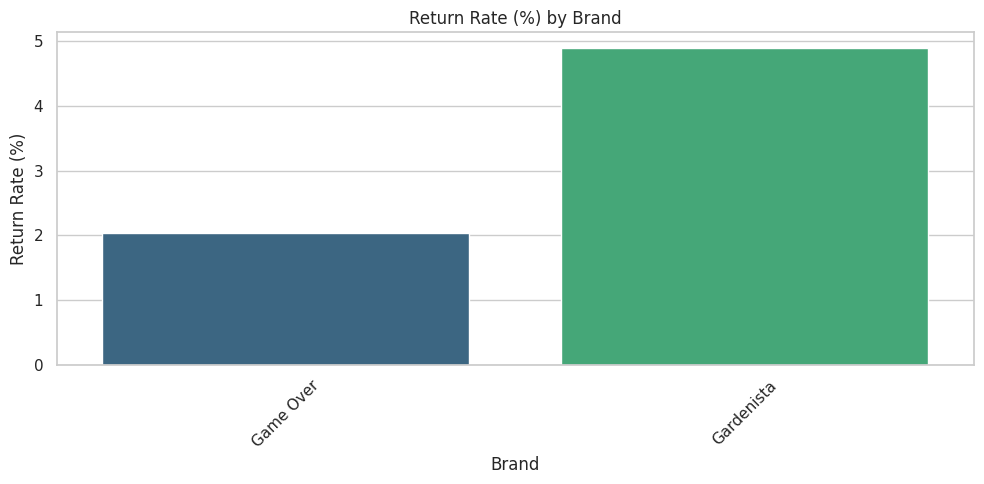

In [7]:
# 3. Return rate and order distribution by Brand
brand_eda = order_lines_df.groupby('Brand').agg(
    Total_Orders=('Order ref', 'count'),
    Return_Rate=('Returned', 'mean'),
    Avg_Line_Value=('Line value inc VAT', 'mean')
).reset_index()

brand_eda['Return_Rate_Pct'] = brand_eda['Return_Rate'] * 100
print("=== Brand Performance & Return Analysis ===")
display(brand_eda)

# Visualizing Returns by Brand
plt.figure(figsize=(10, 5))
sns.barplot(data=brand_eda, x='Brand', y='Return_Rate_Pct', palette='viridis')
plt.title('Return Rate (%) by Brand')
plt.ylabel('Return Rate (%)')
plt.xlabel('Brand')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

=== Channel Performance & Return Analysis ===


,Channel,Total_Orders,Return_Rate,Avg_Line_Value,Return_Rate_Pct
0,Amazon,21678,0.043593,47.173481,4.359258
1,Direct/Manual,332,0.015060,0.921265,1.506024
2,Mirakl MP,11,0.363636,34.017273,36.363636
3,TEMU EU,49,0.061224,38.245918,6.122449
4,The Range,3492,0.064719,48.349728,6.471936
5,TikTok Shop,297,0.067340,15.719259,6.734007
6,Website (Shopify),7047,0.038740,51.151067,3.873989
7,eBay,1399,0.040743,45.236583,4.074339


/tmp/ipykernel_8526/417006436.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=channel_eda, x='Channel', y='Return_Rate_Pct', palette='mako')


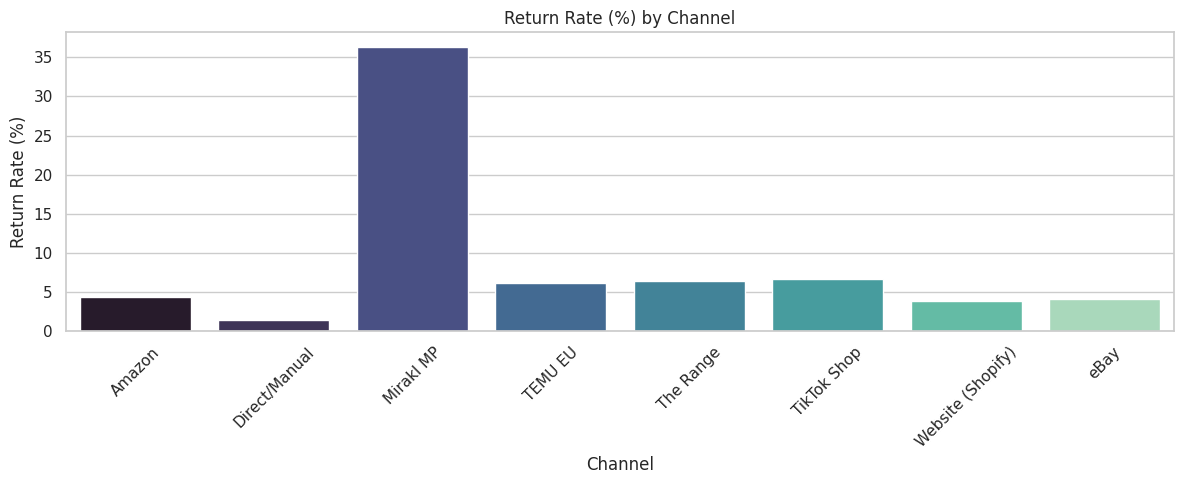

In [8]:
# 4. Return rate and order distribution by Sales Channel
channel_eda = order_lines_df.groupby('Channel').agg(
    Total_Orders=('Order ref', 'count'),
    Return_Rate=('Returned', 'mean'),
    Avg_Line_Value=('Line value inc VAT', 'mean')
).reset_index()

channel_eda['Return_Rate_Pct'] = channel_eda['Return_Rate'] * 100
print("=== Channel Performance & Return Analysis ===")
display(channel_eda)

# Visualizing Returns by Channel
plt.figure(figsize=(12, 5))
sns.barplot(data=channel_eda, x='Channel', y='Return_Rate_Pct', palette='mako')
plt.title('Return Rate (%) by Channel')
plt.ylabel('Return Rate (%)')
plt.xlabel('Channel')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_8526/575891235.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=order_lines_df, x='Returned', y='Line value inc VAT', palette='Set2')


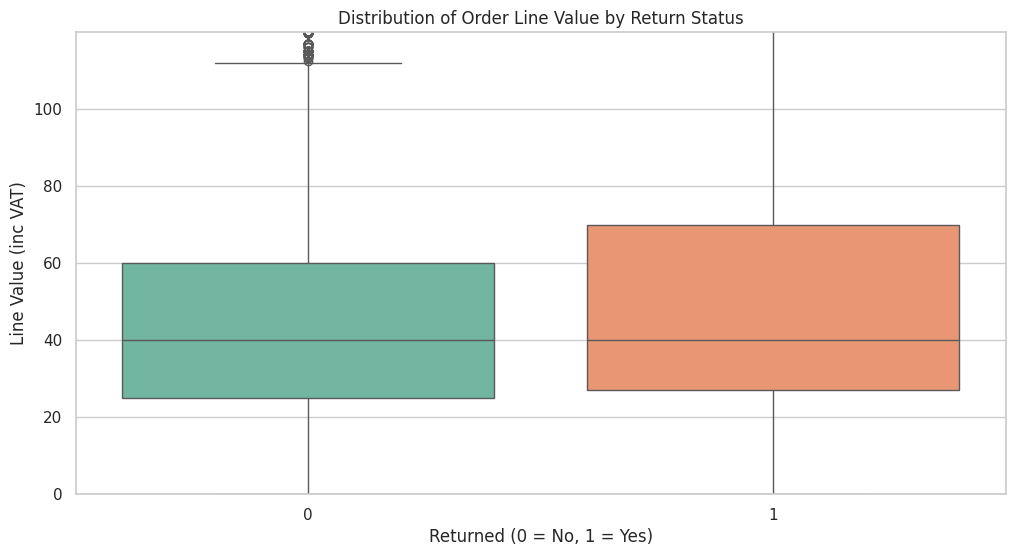

In [10]:
# 5. Distribution of Line Values for Returned vs Non-Returned items
plt.figure(figsize=(12, 6))
sns.boxplot(data=order_lines_df, x='Returned', y='Line value inc VAT', palette='Set2')
plt.title('Distribution of Order Line Value by Return Status')
plt.xlabel('Returned (0 = No, 1 = Yes)')
plt.ylabel('Line Value (inc VAT)')
# Limiting y-axis to see the bulk of the distribution clearly
plt.ylim(0, order_lines_df['Line value inc VAT'].quantile(0.95))
plt.show()